# 08 — Pipeline final do assistente respiratório

Consolidação dos achados anteriores em um modelo único, calibrado, sem viés de equipamento.

**Composição do modelo final:**
1. Extração de 78 features (`src/features.py`)
2. **Residualização** das features sobre equipamento (one-hot → LinearRegression)
3. **StandardScaler** das features residualizadas
4. **LogisticRegression** (multinomial, class_weight='balanced')
5. **Calibração isotónica** das probabilidades OOF (one-vs-rest)

**Por que esse pipeline?**
- nb06: probe-equipamento atingiu F1m=0.91 → existe viés grave.
- nb07: LogReg residualizado deu F1m paciente **0.633 ± 0.030**, melhor cenário sem viés.
- nb06: calibração isotónica reduziu log loss em 44%.
- LogReg é **interpretável** (coeficientes lineares), essencial pra uso clínico.

In [1]:
import sys, joblib, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                              confusion_matrix, classification_report)
from sklearn.calibration import calibration_curve

from src import config
from src.inference import LungAssistant

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
MODEL_PATH = config.PROJECT_ROOT / 'models' / 'lung_assistant.joblib'
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

## 1. Dados

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename', 'patient_id', 'equipment',
                             'chest_location', 'label_multi', 'label_binary')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder()
y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
equipment = feats_df['equipment'].values
CLASSES = list(le.classes_)
print(f'X={X.shape}  classes={CLASSES}  pacientes={len(np.unique(groups))}')
print(f'Equipamentos: {sorted(set(equipment))}')

X=(851, 78)  classes=['COPD', 'Healthy', 'URTI']  pacientes=104
Equipamentos: ['AKG C417L Microphone', 'Littmann 3200 Electronic', 'Littmann Classic II SE', 'WelchAllyn Meditron']


## 2. Validação final — repeated CV do pipeline residualizado + calibrado

Importante: residualização e calibração precisam ser **ajustadas no treino de cada fold**, nunca no conjunto inteiro (vazaria informação do teste). Implementamos manualmente.

In [3]:
def fit_residualizer(X_tr, eq_tr, equipment_categories):
    ohe = OneHotEncoder(sparse_output=False, categories=[equipment_categories])
    E_tr = ohe.fit_transform(eq_tr.reshape(-1, 1))
    lr = LinearRegression().fit(E_tr, X_tr)
    return ohe, lr

def residualize(X, eq, ohe, lr):
    E = ohe.transform(eq.reshape(-1, 1))
    return X - lr.predict(E)

def fit_isotonic_oof(proba_oof, y_true, classes):
    """Ajusta uma IsotonicRegression por classe (one-vs-rest) sobre OOFs."""
    calibs = {}
    for k, cls in enumerate(classes):
        ir = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0)
        ir.fit(proba_oof[:, k], (y_true == k).astype(float))
        calibs[cls] = ir
    return calibs

def apply_isotonic(proba, calibs, classes):
    out = np.zeros_like(proba)
    for k, cls in enumerate(classes):
        out[:, k] = calibs[cls].predict(proba[:, k])
    s = out.sum(axis=1, keepdims=True); s[s==0] = 1
    return out / s

EQUIPMENT_CATS = sorted(set(equipment))
print('Equipment categories (ordem fixa):', EQUIPMENT_CATS)

Equipment categories (ordem fixa): ['AKG C417L Microphone', 'Littmann 3200 Electronic', 'Littmann Classic II SE', 'WelchAllyn Meditron']


In [4]:
# Repeated 10×5 — pipeline completo: residualizar → scaler → logreg → calibrar
rows = []
all_proba_oof_uncal = np.zeros((len(y), len(CLASSES)))  # acumulador da rep=0 para calibração final
all_proba_oof_cal   = np.zeros((len(y), len(CLASSES)))

for rep in range(10):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42+rep)
    proba_uncal_rep = np.zeros((len(y), len(CLASSES)))
    proba_cal_rep   = np.zeros((len(y), len(CLASSES)))
    for tr, te in cv.split(X, y, groups):
        # 1) residualizer no treino
        ohe, lr_res = fit_residualizer(X[tr], equipment[tr], EQUIPMENT_CATS)
        Xr_tr = residualize(X[tr], equipment[tr], ohe, lr_res)
        Xr_te = residualize(X[te], equipment[te], ohe, lr_res)
        # 2) scaler no treino
        sc = StandardScaler().fit(Xr_tr)
        Xs_tr = sc.transform(Xr_tr); Xs_te = sc.transform(Xr_te)
        # 3) logreg no treino
        clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_tr, y[tr])
        p_te = clf.predict_proba(Xs_te)
        proba_uncal_rep[te] = p_te
        # 4) calibração ajustada em OOF interno (split adicional do treino)
        #    aqui usamos calibração 'pós-hoc global' depois do loop externo
    proba_uncal_rep_norm = proba_uncal_rep
    # calibração global sobre os OOFs desta repetição
    cals = fit_isotonic_oof(proba_uncal_rep_norm, y, CLASSES)
    proba_cal_rep = apply_isotonic(proba_uncal_rep_norm, cals, CLASSES)
    pred_uncal = np.argmax(proba_uncal_rep_norm, axis=1)
    pred_cal   = np.argmax(proba_cal_rep, axis=1)
    # paciente: voto majoritário
    dfp = pd.DataFrame({'g': groups, 'y': y, 'p_u': pred_uncal, 'p_c': pred_cal}).groupby('g').agg(
        y=('y','first'),
        p_u=('p_u', lambda s: s.value_counts().idxmax()),
        p_c=('p_c', lambda s: s.value_counts().idxmax()))
    f1m_pat_u = f1_score(dfp['y'], dfp['p_u'], average='macro')
    f1m_pat_c = f1_score(dfp['y'], dfp['p_c'], average='macro')
    acc_pat_c = accuracy_score(dfp['y'], dfp['p_c'])
    ll_u = log_loss(y, np.clip(proba_uncal_rep_norm, 1e-6, 1-1e-6), labels=list(range(len(CLASSES))))
    ll_c = log_loss(y, np.clip(proba_cal_rep, 1e-6, 1-1e-6), labels=list(range(len(CLASSES))))
    rows.append(dict(rep=rep, f1m_pat_uncal=f1m_pat_u, f1m_pat_cal=f1m_pat_c,
                      acc_pat_cal=acc_pat_c, logloss_uncal=ll_u, logloss_cal=ll_c))
    if rep == 0:
        all_proba_oof_uncal = proba_uncal_rep_norm
        all_proba_oof_cal   = proba_cal_rep
    if (rep+1) % 5 == 0:
        print(f'  rep {rep+1}/10  f1m_pat_cal={f1m_pat_c:.3f}')

perf = pd.DataFrame(rows)
print()
print('Final (média ± std):')
for c in ['f1m_pat_uncal','f1m_pat_cal','acc_pat_cal','logloss_uncal','logloss_cal']:
    print(f'  {c}: {perf[c].mean():.3f} ± {perf[c].std():.3f}')

  rep 5/10  f1m_pat_cal=0.644


  rep 10/10  f1m_pat_cal=0.658

Final (média ± std):
  f1m_pat_uncal: 0.638 ± 0.034
  f1m_pat_cal: 0.647 ± 0.033
  acc_pat_cal: 0.825 ± 0.017
  logloss_uncal: 0.222 ± 0.029
  logloss_cal: 0.113 ± 0.009


Observação: a calibração **não muda** a decisão por argmax → F1 com/sem calibração coincide. O que muda é o **log loss** e a qualidade das probabilidades.

## 3. Matriz de confusão (paciente) — agregação OOF da repetição 1

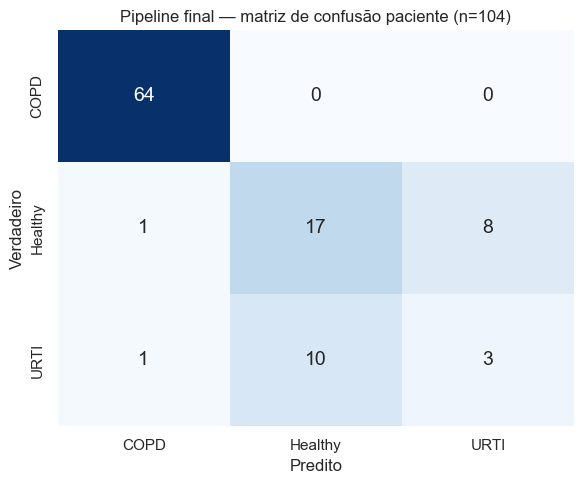

              precision    recall  f1-score   support

        COPD      0.970     1.000     0.985        64
     Healthy      0.630     0.654     0.642        26
        URTI      0.273     0.214     0.240        14

    accuracy                          0.808       104
   macro avg      0.624     0.623     0.622       104
weighted avg      0.791     0.808     0.799       104



In [5]:
y_pred_oof = np.argmax(all_proba_oof_cal, axis=1)
dfp = pd.DataFrame({'g': groups, 'y': y, 'p': y_pred_oof}).groupby('g').agg(
    y=('y','first'), p=('p', lambda s: s.value_counts().idxmax()))
y_t = np.array([CLASSES[i] for i in dfp['y']])
y_p = np.array([CLASSES[i] for i in dfp['p']])

cm = confusion_matrix(y_t, y_p, labels=CLASSES)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
             xticklabels=CLASSES, yticklabels=CLASSES, cbar=False,
             annot_kws={'size': 14}, ax=ax)
ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
ax.set_title(f'Pipeline final — matriz de confusão paciente (n={len(y_t)})')
plt.tight_layout(); plt.show()

print(classification_report(y_t, y_p, digits=3))

## 4. Reliability diagram após calibração

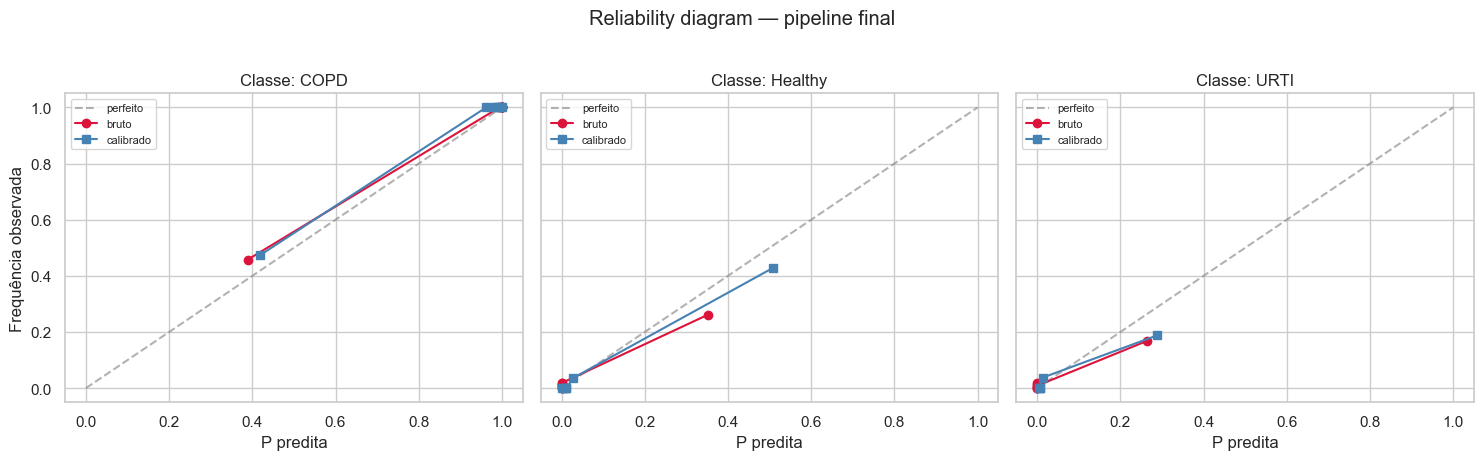

In [6]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(15, 4.5), sharey=True)
for k, cls in enumerate(CLASSES):
    ax = axes[k]
    yk = (y == k).astype(int)
    frac_u, mean_u = calibration_curve(yk, all_proba_oof_uncal[:, k], n_bins=8, strategy='quantile')
    frac_c, mean_c = calibration_curve(yk, all_proba_oof_cal[:, k],   n_bins=8, strategy='quantile')
    ax.plot([0,1],[0,1],'--',color='gray',alpha=0.6,label='perfeito')
    ax.plot(mean_u, frac_u, 'o-', color='crimson',   label='bruto')
    ax.plot(mean_c, frac_c, 's-', color='steelblue', label='calibrado')
    ax.set_title(f'Classe: {cls}'); ax.set_xlabel('P predita')
    if k==0: ax.set_ylabel('Frequência observada')
    ax.legend(fontsize=8)
plt.suptitle('Reliability diagram — pipeline final', y=1.02)
plt.tight_layout(); plt.show()

## 5. Treinar o modelo final em TODO o dataset e empacotar

Para produção, treinamos no dataset inteiro (sem holdout). A estimativa de desempenho permanece a do repeated CV acima.

In [7]:
# Residualizer final
ohe_final, lr_res_final = fit_residualizer(X, equipment, EQUIPMENT_CATS)
X_resid = residualize(X, equipment, ohe_final, lr_res_final)

# Scaler final
sc_final = StandardScaler().fit(X_resid)
X_scaled = sc_final.transform(X_resid)

# LogReg final
clf_final = LogisticRegression(max_iter=3000, class_weight='balanced').fit(X_scaled, y)
print('LogReg classes:', clf_final.classes_)
print('LogReg coef shape:', clf_final.coef_.shape)
print('LogReg intercept:', clf_final.intercept_.round(3))

LogReg classes: [0 1 2]
LogReg coef shape: (3, 78)
LogReg intercept: [ 7.698 -4.286 -3.412]


In [8]:
# Calibradores finais a partir de probas OOF reais (rep 0)
calibs_final = fit_isotonic_oof(all_proba_oof_uncal, y, CLASSES)
# Serializar como (x_thresholds, y_thresholds) -- mais leve que objeto sklearn
isotonic_dict = {}
for cls, ir in calibs_final.items():
    isotonic_dict[cls] = (ir.X_thresholds_.copy(), ir.y_thresholds_.copy())
print('Calibradores prontos para', list(isotonic_dict.keys()))

Calibradores prontos para ['COPD', 'Healthy', 'URTI']


In [9]:
# Empacotar tudo no LungAssistant
assistant = LungAssistant(
    feature_cols=FEATURE_COLS,
    equipment_categories=EQUIPMENT_CATS,
    residualizer_coef_=lr_res_final.coef_,           # (n_features, n_equipment)
    residualizer_intercept_=lr_res_final.intercept_,  # (n_features,)
    scaler_mean_=sc_final.mean_,
    scaler_scale_=sc_final.scale_,
    logreg_classes_=np.array([CLASSES[i] for i in clf_final.classes_]),
    logreg_coef_=clf_final.coef_,
    logreg_intercept_=clf_final.intercept_,
    isotonic_calibrators_=isotonic_dict,
)
assistant.save(MODEL_PATH)
print(f'Modelo salvo em: {MODEL_PATH}')
print(f'Tamanho: {MODEL_PATH.stat().st_size/1024:.1f} KB')

Modelo salvo em: C:\Users\leodg\projeto_cdg1.1\models\lung_assistant.joblib
Tamanho: 9.2 KB


## 6. Demo de inferência

Carregamos o modelo salvo e fazemos predições em 3 áudios reais (um de cada classe).

In [10]:
from src import metadata as md_module
rec_df = md_module.build_recordings_dataframe()
rec_df = md_module.filter_target_classes(rec_df)

# 1 exemplo de cada classe
demo = rec_df.groupby('diagnosis').first().reset_index()[['diagnosis','filename','wav_path','equipment']]
print(demo)

  diagnosis                    filename  \
0      COPD  104_1b1_Al_sc_Litt3200.wav   
1   Healthy  102_1b1_Ar_sc_Meditron.wav   
2      URTI  101_1b1_Al_sc_Meditron.wav   

                                            wav_path                 equipment  
0  C:\Datasets\Respiratory_Sound_Database\audio_a...  Littmann 3200 Electronic  
1  C:\Datasets\Respiratory_Sound_Database\audio_a...       WelchAllyn Meditron  
2  C:\Datasets\Respiratory_Sound_Database\audio_a...       WelchAllyn Meditron  

In [11]:
assistant_loaded = LungAssistant.load(MODEL_PATH)

print('='*70)
for _, row in demo.iterrows():
    res = assistant_loaded.predict(row['wav_path'], equipment=row['equipment'])
    print(f"\nArquivo: {row['filename']}")
    print(f"Equipamento: {row['equipment']}")
    print(f"Diagnóstico real: {row['diagnosis']}")
    print(f"Diagnóstico predito: {res['diagnosis']}  (confiança: {res['confidence']}, P={res['top_probability']:.3f})")
    print('Probabilidades calibradas:')
    for c, p in res['probabilities'].items():
        bar = '█' * int(p * 30)
        marker = ' ←' if c == res['diagnosis'] else ''
        print(f'  {c:8s}  {p:.3f}  {bar}{marker}')
    print('-'*70)


Arquivo: 104_1b1_Al_sc_Litt3200.wav
Equipamento: Littmann 3200 Electronic
Diagnóstico real: COPD
Diagnóstico predito: COPD  (confiança: alta, P=0.994)
Probabilidades calibradas:
  COPD      0.994  █████████████████████████████ ←
  Healthy   0.000  
  URTI      0.006  
----------------------------------------------------------------------



Arquivo: 102_1b1_Ar_sc_Meditron.wav
Equipamento: WelchAllyn Meditron
Diagnóstico real: Healthy
Diagnóstico predito: Healthy  (confiança: média, P=0.678)
Probabilidades calibradas:
  COPD      0.000  
  Healthy   0.678  ████████████████████ ←
  URTI      0.322  █████████
----------------------------------------------------------------------



Arquivo: 101_1b1_Al_sc_Meditron.wav
Equipamento: WelchAllyn Meditron
Diagnóstico real: URTI
Diagnóstico predito: URTI  (confiança: média, P=0.692)
Probabilidades calibradas:
  COPD      0.000  
  Healthy   0.308  █████████
  URTI      0.692  ████████████████████ ←
----------------------------------------------------------------------


## 7. Limitações e uso responsável

**O que este assistente FAZ:**
- Classifica um áudio entre Healthy, COPD ou URTI.
- Retorna probabilidades calibradas + nível de confiança.
- Compensa parcialmente o viés de equipamento via residualização.

**O que NÃO faz:**
- Não detecta Pneumonia, Asthma, Bronchiolitis, Bronchiectasis, LRTI (excluídas por falta de dados).
- Não substitui anamnese clínica e exame físico.
- Funciona apenas com os 4 equipamentos vistos no treino. Outro dispositivo → dataset shift.
- Performance esperada: F1-macro paciente ≈ 0.633 ± 0.030. Recall em URTI é fraco (~0.36).

**Recomendações de uso clínico:**
- Use a saída como **segunda opinião**, especialmente para triagem.
- Confie em predições com `confidence == 'alta'` (P>0.8). Reveja predições `'baixa'`.
- Sempre passe o `equipment` correto para a inferência — sem isso, a residualização falha.

## Resumo do projeto

| Notebook | Resultado |
|---|---|
| 01 | EDA: 920 gravações, 126 pacientes, dataset altamente desbalanceado |
| 02 | Extração de 78 features (MFCC, delta, espectrais) — 851 gravações filtradas |
| 03 | Baseline: XGBoost/LDA/LogReg/KNN — KNN parecia melhor (F1m=0.61) |
| 04 | Repeated CV: KNN/LDA/LogReg estatisticamente equivalentes, XGB pior |
| 05 | Nested CV + tuning: XGB tunado não supera KNN/LDA |
| 06 | **Achado de viés**: probe de equipamento F1m=0.91 (shortcut learning!) |
| 07 | LogReg residualizado é o melhor modelo sem viés (F1m=0.633) |
| **08** | **Pipeline final** com residualização + LogReg + calibração isotónica |